# Week 3 - Feature Selection and Component Regression

## Introduction

This notebook applies forward selection, backward selection, Principal Component Regression (PCR), and Partial Least Squares Regression (PLSR) to three digital marketing datasets.The goal is to investigate whether selecting important predictors or reducing the predictors into components can improve model performance. Models will be evaluated using training and testing R² and RMSE. Visualizations will also be used to compare feature selection and component-based model performance.

### Datasets
1. Digital Marketing Campaign
2. Marketing and Product Performance
3. Companies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error

sns.set_theme(style="whitegrid")

In [ ]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing Dataset:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Companies: (734, 19)


In [3]:
features1 = [
    "AdSpend",
    "ClickThroughRate",
    "WebsiteVisits",
    "TimeOnSite",
    "EmailClicks"
]

X1 = df1[features1]
y1 = df1["ConversionRate"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

baseline1 = LinearRegression()
baseline1.fit(X1_train, y1_train)

baseline1_pred = baseline1.predict(X1_test)

print("Training R²:", round(baseline1.score(X1_train, y1_train), 4))
print("Testing R²:", round(r2_score(y1_test, baseline1_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y1_test, baseline1_pred)), 4))

Training R²: 0.0007
Testing R²: -0.0009
Testing RMSE: 0.0541


### Forward Selection

Forward selection begins with no predictors and gradually adds features that improve model performance. Models containing different numbers of selected features will be compared using cross-validation.

In [ ]:
#forward selection with different numbers of features
forward_results1 = []

for n in range(1, len(features1)):
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=n,
        direction="forward",
        scoring="neg_mean_squared_error",
        cv=5
    )

    selector.fit(X1_train, y1_train)
    selected = X1_train.columns[selector.get_support()].tolist()

    model = LinearRegression()
    model.fit(X1_train[selected], y1_train)
    pred = model.predict(X1_test[selected])

    forward_results1.append({
        "Number of Features": n,
        "Selected Features": ", ".join(selected),
        "Testing R²": r2_score(y1_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y1_test, pred))
    })

# Add full model for comparison
forward_results1.append({
    "Number of Features": 5,
    "Selected Features": ", ".join(features1),
    "Testing R²": r2_score(y1_test, baseline1_pred),
    "Testing RMSE": np.sqrt(mean_squared_error(y1_test, baseline1_pred))
})

forward_results1 = pd.DataFrame(forward_results1)
forward_results1

,Number of Features,Selected Features,Testing R²,Testing RMSE
0,1,AdSpend,-0.001556,0.054074
1,2,"AdSpend, WebsiteVisits",-0.001156,0.054063
2,3,"AdSpend, WebsiteVisits, EmailClicks",-0.001305,0.054067
3,4,"AdSpend, WebsiteVisits, TimeOnSite, EmailClicks",-0.001133,0.054063
4,5,"AdSpend, ClickThroughRate, WebsiteVisits, Time...",-0.000933,0.054057


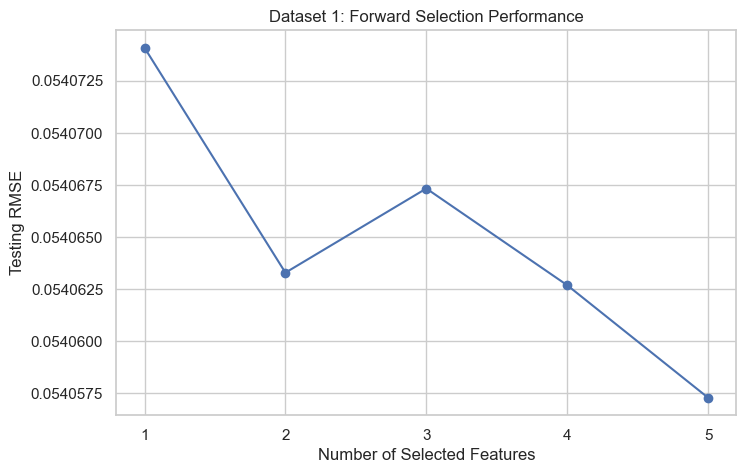

In [ ]:
# plotting forward selection performance
plt.figure(figsize=(8, 5))

plt.plot(
    forward_results1["Number of Features"],
    forward_results1["Testing RMSE"],
    marker="o"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Testing RMSE")
plt.title("Dataset 1: Forward Selection Performance")
plt.xticks(range(1, 6))
plt.show()

Forward selection showed only very small differences in model performance as predictors were added. AdSpend was selected first, followed by WebsiteVisits, EmailClicks, and TimeOnSite. The full five-feature model produced the lowest testing RMSE of approximately 0.05406 and the highest testing R². The results suggest that reducing the number of predictors did not improve prediction of ConversionRate. Overall performance remained weak, with negative testing R² values for every model.

### Backward Selection

Backward selection begins with all available predictors and removes features while attempting to maintain model performance.

In [ ]:
# backward selection with different numbers of features
backward_results1 = []

for n in range(1, len(features1)):
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=n,
        direction="backward",
        scoring="neg_mean_squared_error",
        cv=5
    )

    selector.fit(X1_train, y1_train)
    selected = X1_train.columns[selector.get_support()].tolist()
    model = LinearRegression()
    model.fit(X1_train[selected], y1_train)
    pred = model.predict(X1_test[selected])
    backward_results1.append({
        "Number of Features": n,
        "Selected Features": ", ".join(selected),
        "Testing R²": r2_score(y1_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y1_test, pred))
    })

# add full model for comparison
backward_results1.append({
    "Number of Features": 5,
    "Selected Features": ", ".join(features1),
    "Testing R²": r2_score(y1_test, baseline1_pred),
    "Testing RMSE": np.sqrt(mean_squared_error(y1_test, baseline1_pred))
})

backward_results1 = pd.DataFrame(backward_results1)
backward_results1

,Number of Features,Selected Features,Testing R²,Testing RMSE
0,1,AdSpend,-0.001556,0.054074
1,2,"AdSpend, WebsiteVisits",-0.001156,0.054063
2,3,"AdSpend, WebsiteVisits, EmailClicks",-0.001305,0.054067
3,4,"AdSpend, WebsiteVisits, TimeOnSite, EmailClicks",-0.001133,0.054063
4,5,"AdSpend, ClickThroughRate, WebsiteVisits, Time...",-0.000933,0.054057


Backward selection produced the same selected feature combinations as forward selection. As the number of predictors increased, model performance changed only slightly. The full five-feature model again produced the lowest testing RMSE of approximately 0.05406 and the highest testing R². Because forward and backward selection produced the same results, both methods suggest that removing predictors does not improve prediction of ConversionRate for this dataset.

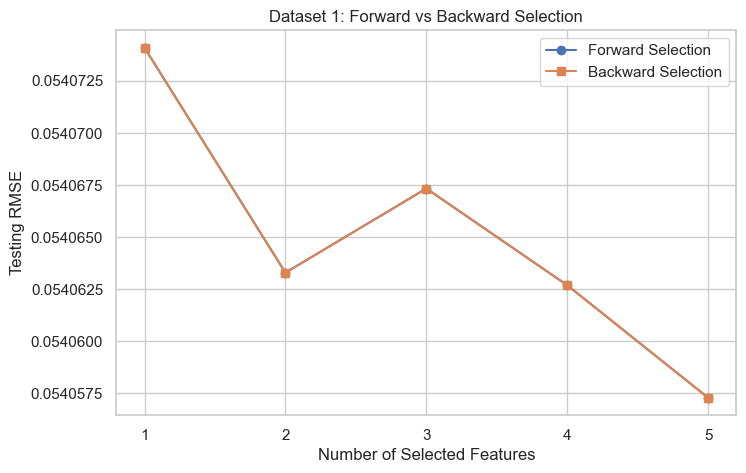

In [ ]:
# Compare forward and backward selection
plt.figure(figsize=(8, 5))
plt.plot(
    forward_results1["Number of Features"],
    forward_results1["Testing RMSE"],
    marker="o",
    label="Forward Selection"
)
plt.plot(
    backward_results1["Number of Features"],
    backward_results1["Testing RMSE"],
    marker="s",
    label="Backward Selection"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Testing RMSE")
plt.title("Dataset 1: Forward vs Backward Selection")
plt.xticks(range(1, 6))
plt.legend()
plt.show()

### Principal Component Regression

Principal Component Regression reduces the original predictors into principal components before fitting a linear regression model. Models with different numbers of components will be compared to determine whether dimensionality reduction improves prediction.

In [10]:
# PCR with different numbers of components
pcr_results1 = []

for n in range(1, len(features1) + 1):
    pcr = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("regression", LinearRegression())
    ])

    pcr.fit(X1_train, y1_train)
    pred = pcr.predict(X1_test)

    pcr_results1.append({
        "Components": n,
        "Testing R²": r2_score(y1_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y1_test, pred))
    })

pcr_results1 = pd.DataFrame(pcr_results1)
pcr_results1

,Components,Testing R²,Testing RMSE
0,1,-0.001202,0.054065
1,2,-0.000899,0.054056
2,3,-0.000745,0.054052
3,4,-0.001076,0.054061
4,5,-0.000933,0.054057


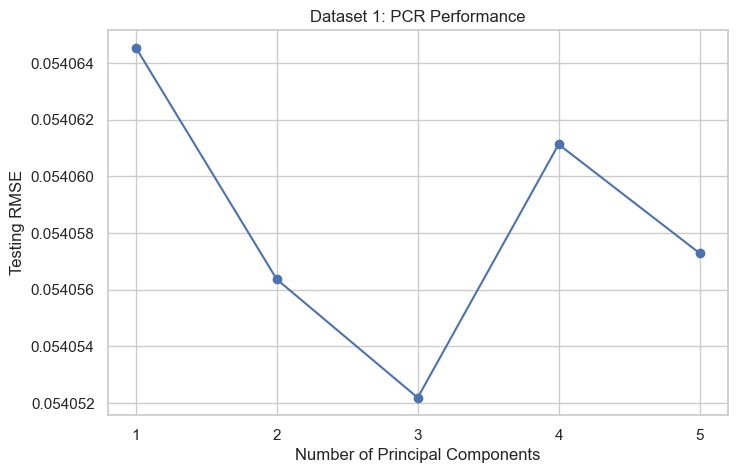

In [11]:
# Plot PCR performance
plt.figure(figsize=(8, 5))

plt.plot(
    pcr_results1["Components"],
    pcr_results1["Testing RMSE"],
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Testing RMSE")
plt.title("Dataset 1: PCR Performance")
plt.xticks(range(1, 6))

plt.show()

PCR performance changed slightly as the number of principal components increased. The three-component model produced the lowest testing RMSE of 0.054052 and the highest testing R² of -0.000745. This was a slight improvement over the original five-feature linear regression model. However, the differences were very small and the testing R² remained negative, indicating limited predictive performance. The results suggest that reducing the five original predictors to three principal components provided a small improvement, but dimensionality reduction did not substantially improve prediction of ConversionRate.

### Partial Least Squares Regression

Partial Least Squares Regression creates components using information from both the predictors and the target variable. Models with different numbers of components will be compared to determine the number of components that provides the best predictive performance.

In [12]:
# PLSR with different numbers of components
plsr_results1 = []

for n in range(1, len(features1) + 1):
    plsr = Pipeline([
        ("scaler", StandardScaler()),
        ("plsr", PLSRegression(n_components=n))
    ])

    plsr.fit(X1_train, y1_train)
    pred = plsr.predict(X1_test).ravel()

    plsr_results1.append({
        "Components": n,
        "Testing R²": r2_score(y1_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y1_test, pred))
    })

plsr_results1 = pd.DataFrame(plsr_results1)
plsr_results1

,Components,Testing R²,Testing RMSE
0,1,-0.000901,0.054056
1,2,-0.000933,0.054057
2,3,-0.000933,0.054057
3,4,-0.000933,0.054057
4,5,-0.000933,0.054057


PLSR achieved its best performance using one component, with a testing R² of -0.000901 and a testing RMSE of 0.054056. Adding additional components did not improve model performance. After two components, the results remained nearly identical. Compared with PCR, the three-component PCR model produced a slightly lower testing RMSE. However, the differences between the models were very small and all testing R² values remained negative.

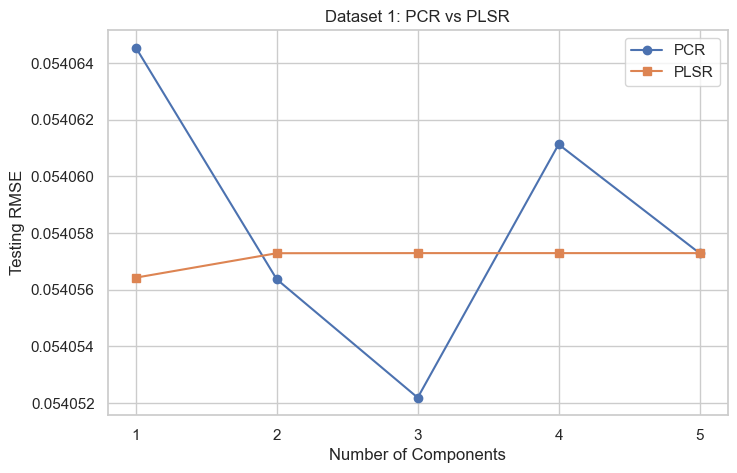

In [ ]:
# Compare PCR and PLSR performance
plt.figure(figsize=(8, 5))

plt.plot(
    pcr_results1["Components"],
    pcr_results1["Testing RMSE"],
    marker="o",
    label="PCR"
)
plt.plot(
    plsr_results1["Components"],
    plsr_results1["Testing RMSE"],
    marker="s",
    label="PLSR"
)

plt.xlabel("Number of Components")
plt.ylabel("Testing RMSE")
plt.title("Dataset 1: PCR vs PLSR")
plt.xticks(range(1, 6))
plt.legend()\
plt.show()

### Dataset 1 Conclusion

Forward and backward selection produced the same feature combinations and did not improve performance compared with the full linear regression model. Both methods showed that removing predictors provided little benefit. PCR produced the best overall result using three principal components, with a testing RMSE of 0.054052. PLSR performed best using one component, with a testing RMSE of 0.054056. Although PCR produced the lowest RMSE, the differences between all models were very small. Testing R² remained negative across the models, indicating that the selected predictors have limited ability to predict ConversionRate.

## Dataset 2: Marketing and Product Performance

The target variable is Revenue_Generated. The predictors are Budget, Clicks, Conversions, Units_Sold, and Bundle_Price.Forward and backward selection will be used to evaluate different predictor subsets. PCR and PLSR will then be used to evaluate whether component-based approaches improve prediction.

In [14]:
features2 = [
    "Budget",
    "Clicks",
    "Conversions",
    "Units_Sold",
    "Bundle_Price"
]

X2 = df2[features2]
y2 = df2["Revenue_Generated"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

baseline2 = LinearRegression()
baseline2.fit(X2_train, y2_train)

baseline2_pred = baseline2.predict(X2_test)

print("Training R²:", round(baseline2.score(X2_train, y2_train), 4))
print("Testing R²:", round(r2_score(y2_test, baseline2_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y2_test, baseline2_pred)), 4))

Training R²: 0.0007
Testing R²: -0.0012
Testing RMSE: 28572.378


### Forward Selection

Forward selection was used to determine whether a smaller subset of predictors could improve the prediction of Revenue_Generated.

In [ ]:
# Forward selection
forward_results2 = []

for n in range(1, len(features2)):
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=n,
        direction="forward",
        scoring="neg_mean_squared_error",
        cv=5
    )

    selector.fit(X2_train, y2_train)
    selected = X2_train.columns[selector.get_support()].tolist()
    model = LinearRegression()
    model.fit(X2_train[selected], y2_train)
    pred = model.predict(X2_test[selected])

    forward_results2.append({
        "Number of Features": n,
        "Selected Features": ", ".join(selected),
        "Testing R²": r2_score(y2_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y2_test, pred))
    })

# Add full model for comparison
forward_results2.append({
    "Number of Features": 5,
    "Selected Features": ", ".join(features2),
    "Testing R²": r2_score(y2_test, baseline2_pred),
    "Testing RMSE": np.sqrt(mean_squared_error(y2_test, baseline2_pred))
})

forward_results2 = pd.DataFrame(forward_results2)
forward_results2

,Number of Features,Selected Features,Testing R²,Testing RMSE
0,1,Budget,-0.001358,28575.105804
1,2,"Budget, Bundle_Price",-0.001386,28575.501532
2,3,"Budget, Clicks, Bundle_Price",-0.001236,28573.355849
3,4,"Budget, Clicks, Units_Sold, Bundle_Price",-0.001018,28570.254910
4,5,"Budget, Clicks, Conversions, Units_Sold, Bundl...",-0.001167,28572.378006


Forward selection showed that the four-feature model produced the best testing performance. This model included Budget, Clicks, Units_Sold, and Bundle_Price while excluding Conversions. The four-feature model achieved a testing R² of -0.001018 and a testing RMSE of 28,570.25, compared with 28,572.38 for the full five-feature model.Although the improvement was small, the results suggest that removing Conversions slightly improved model performance. Testing R² remained negative, indicating that the predictors still provide limited ability to predict Revenue_Generated.

In [ ]:
# Backward selection
backward_results2 = []

for n in range(1, len(features2)):
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=n,
        direction="backward",
        scoring="neg_mean_squared_error",
        cv=5
    )

    selector.fit(X2_train, y2_train)
    selected = X2_train.columns[selector.get_support()].tolist()
    model = LinearRegression()
    model.fit(X2_train[selected], y2_train)
    pred = model.predict(X2_test[selected])

    backward_results2.append({
        "Number of Features": n,
        "Selected Features": ", ".join(selected),
        "Testing R²": r2_score(y2_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y2_test, pred))
    })

# Add full model for comparison
backward_results2.append({
    "Number of Features": 5,
    "Selected Features": ", ".join(features2),
    "Testing R²": r2_score(y2_test, baseline2_pred),
    "Testing RMSE": np.sqrt(mean_squared_error(y2_test, baseline2_pred))
})

backward_results2 = pd.DataFrame(backward_results2)
backward_results2

,Number of Features,Selected Features,Testing R²,Testing RMSE
0,1,Budget,-0.001358,28575.105804
1,2,"Budget, Bundle_Price",-0.001386,28575.501532
2,3,"Budget, Clicks, Bundle_Price",-0.001236,28573.355849
3,4,"Budget, Clicks, Units_Sold, Bundle_Price",-0.001018,28570.254910
4,5,"Budget, Clicks, Conversions, Units_Sold, Bundl...",-0.001167,28572.378006


### Backward Selection Findings

Backward selection produced the same feature combinations and model performance as forward selection. Both methods found that the four-feature model performed best. This model included Budget, Clicks, Units_Sold, and Bundle_Price while excluding Conversions.
The four-feature model achieved a testing RMSE of 28,570.25, slightly lower than the full model's RMSE of 28,572.38. However, testing R² remained negative, indicating limited predictive performance.

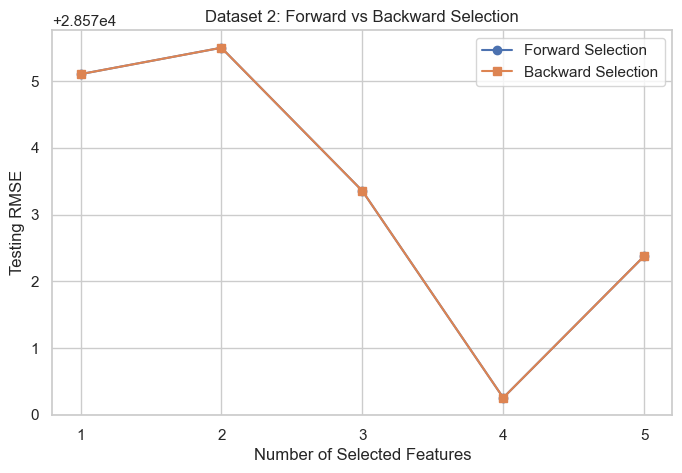

In [ ]:
# Compare forward and backward selection
plt.figure(figsize=(8, 5))
plt.plot(
    forward_results2["Number of Features"],
    forward_results2["Testing RMSE"],
    marker="o",
    label="Forward Selection"
)
plt.plot(
    backward_results2["Number of Features"],
    backward_results2["Testing RMSE"],
    marker="s",
    label="Backward Selection"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Testing RMSE")
plt.title("Dataset 2: Forward vs Backward Selection")
plt.xticks(range(1, 6))
plt.legend()
plt.show()

### Principal Component Regression

PCR was applied to determine whether reducing the five original predictors into a smaller number of principal components could improve prediction of Revenue_Generated.

In [19]:
# PCR with different numbers of components
pcr_results2 = []

for n in range(1, len(features2) + 1):
    pcr = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("regression", LinearRegression())
    ])

    pcr.fit(X2_train, y2_train)
    pred = pcr.predict(X2_test)

    pcr_results2.append({
        "Components": n,
        "Testing R²": r2_score(y2_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y2_test, pred))
    })

pcr_results2 = pd.DataFrame(pcr_results2)
pcr_results2

,Components,Testing R²,Testing RMSE
0,1,-0.000633,28564.757591
1,2,-0.001210,28572.992309
2,3,-0.001784,28581.172903
3,4,-0.001566,28578.069924
4,5,-0.001167,28572.378006


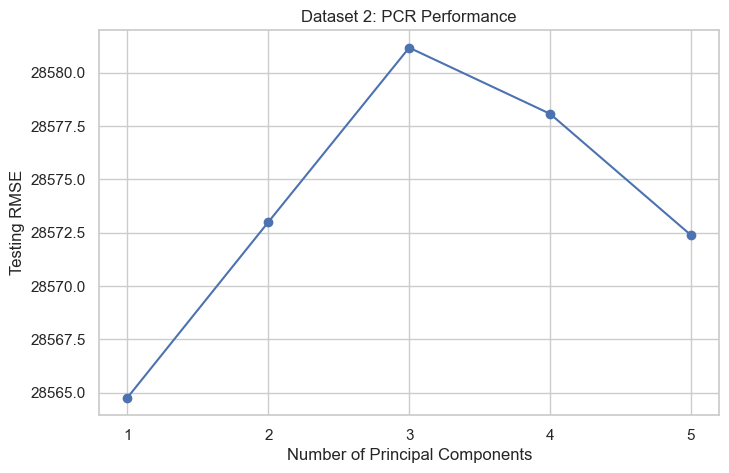

In [20]:
# Plot PCR performance
plt.figure(figsize=(8, 5))

plt.plot(
    pcr_results2["Components"],
    pcr_results2["Testing RMSE"],
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Testing RMSE")
plt.title("Dataset 2: PCR Performance")
plt.xticks(range(1, 6))

plt.show()

PCR achieved its best performance using one principal component, with a testing R² of -0.000633 and a testing RMSE of 28,564.76. This was slightly better than both the full linear regression model and the best forward and backward selection models. Adding more principal components did not improve testing performance. Although the one-component PCR model produced the lowest RMSE so far, the testing R² remained negative, indicating that predictive performance is still limited.

### Partial Least Squares Regression

PLSR was applied to determine whether components created using information from both the predictors and Revenue_Generated could improve predictive performance.

In [21]:
# PLSR with different numbers of components
plsr_results2 = []

for n in range(1, len(features2) + 1):
    plsr = Pipeline([
        ("scaler", StandardScaler()),
        ("plsr", PLSRegression(n_components=n))
    ])

    plsr.fit(X2_train, y2_train)
    pred = plsr.predict(X2_test).ravel()

    plsr_results2.append({
        "Components": n,
        "Testing R²": r2_score(y2_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y2_test, pred))
    })

plsr_results2 = pd.DataFrame(plsr_results2)
plsr_results2

,Components,Testing R²,Testing RMSE
0,1,-0.001196,28572.785151
1,2,-0.001168,28572.386939
2,3,-0.001167,28572.377872
3,4,-0.001167,28572.378003
4,5,-0.001167,28572.378006


PLSR produced very similar results across the different numbers of components. The three-component model produced the lowest testing RMSE of approximately 28,572.38. Increasing the number of components beyond three did not meaningfully change model performance. Compared with PCR, PLSR did not improve prediction of Revenue_Generated. The one-component PCR model remained the best-performing model for this dataset, although all testing R² values remained negative.

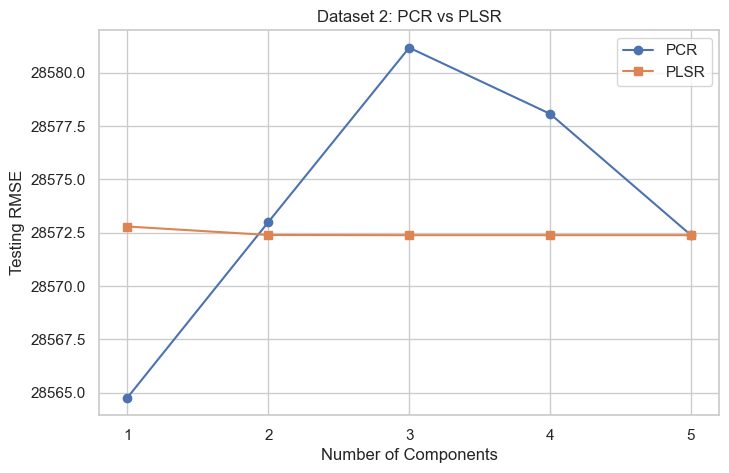

In [ ]:
# Compare PCR and PLSR performance
plt.figure(figsize=(8, 5))

plt.plot(
    pcr_results2["Components"],
    pcr_results2["Testing RMSE"],
    marker="o",
    label="PCR"
)

plt.plot(
    plsr_results2["Components"],
    plsr_results2["Testing RMSE"],
    marker="s",
    label="PLSR"
)

plt.xlabel("Number of Components")
plt.ylabel("Testing RMSE")
plt.title("Dataset 2: PCR vs PLSR")
plt.xticks(range(1, 6))
plt.legend()
plt.show()

### Dataset 2 Conclusion

Forward and backward selection produced the same results, with the four-feature model slightly outperforming the full model. Both methods excluded Conversions from the best reduced model. PCR produced the best overall performance using one principal component, with a testing RMSE of 28,564.76. PLSR produced similar results across its component models but did not outperform PCR. Although feature selection and PCR produced small improvements, testing R² remained negative across all approaches. This indicates that the selected predictors provide limited ability to predict Revenue_Generated.

## Dataset 3: Synthetic B2B CRM & Marketing Dataset

The target variable is Leads_Generated. The predictors are Annual_Revenue (M₺), Marketing_Spend (K₺), Days_Since_Last_Purchase, and Total_Purchases_Last_Year. Forward and backward selection will be used to evaluate different predictor subsets. PCR and PLSR will then be used to determine whether component-based approaches improve prediction.

In [ ]:
features3 = [
    "Annual_Revenue (M₺)",
    "Marketing_Spend (K₺)",
    "Days_Since_Last_Purchase",
    "Total_Purchases_Last_Year"
]

X3 = df3[features3]
y3 = df3["Leads_Generated"]

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42
)

baseline3 = LinearRegression()
baseline3.fit(X3_train, y3_train)
baseline3_pred = baseline3.predict(X3_test)

print("Training R²:", round(baseline3.score(X3_train, y3_train), 4))
print("Testing R²:", round(r2_score(y3_test, baseline3_pred), 4))
print("Testing RMSE:", round(np.sqrt(mean_squared_error(y3_test, baseline3_pred)), 4))

Training R²: 0.0232
Testing R²: -0.0218
Testing RMSE: 3.0941


### Forward Selection

Forward selection was used to determine whether a smaller subset of predictors could improve the prediction of Leads_Generated.

In [25]:
# Forward selection
forward_results3 = []

for n in range(1, len(features3)):
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=n,
        direction="forward",
        scoring="neg_mean_squared_error",
        cv=5
    )

    selector.fit(X3_train, y3_train)
    selected = X3_train.columns[selector.get_support()].tolist()

    model = LinearRegression()
    model.fit(X3_train[selected], y3_train)
    pred = model.predict(X3_test[selected])

    forward_results3.append({
        "Number of Features": n,
        "Selected Features": ", ".join(selected),
        "Testing R²": r2_score(y3_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y3_test, pred))
    })

# Add full model for comparison
forward_results3.append({
    "Number of Features": 4,
    "Selected Features": ", ".join(features3),
    "Testing R²": r2_score(y3_test, baseline3_pred),
    "Testing RMSE": np.sqrt(mean_squared_error(y3_test, baseline3_pred))
})

forward_results3 = pd.DataFrame(forward_results3)
forward_results3

,Number of Features,Selected Features,Testing R²,Testing RMSE
0,1,Marketing_Spend (K₺),0.003588,3.055426
1,2,"Annual_Revenue (M₺), Marketing_Spend (K₺)",-0.009576,3.075542
2,3,"Annual_Revenue (M₺), Marketing_Spend (K₺), Tot...",-0.018876,3.089675
3,4,"Annual_Revenue (M₺), Marketing_Spend (K₺), Day...",-0.021794,3.094097


Forward selection showed that the one-feature model using Marketing Spend produced the best testing performance. This model achieved a testing R² of 0.003588 and a testing RMSE of 3.0554, compared with a testing R² of -0.0218 and RMSE of 3.0941 for the full four-feature model. Adding additional predictors gradually reduced testing performance. Although the positive R² is very small, this was the first Week 3 model to achieve a positive testing R², suggesting that Marketing Spend alone provided slightly better predictive performance than the larger feature combinations.

In [26]:
# Backward selection
backward_results3 = []

for n in range(1, len(features3)):
    selector = SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=n,
        direction="backward",
        scoring="neg_mean_squared_error",
        cv=5
    )

    selector.fit(X3_train, y3_train)
    selected = X3_train.columns[selector.get_support()].tolist()

    model = LinearRegression()
    model.fit(X3_train[selected], y3_train)
    pred = model.predict(X3_test[selected])

    backward_results3.append({
        "Number of Features": n,
        "Selected Features": ", ".join(selected),
        "Testing R²": r2_score(y3_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y3_test, pred))
    })

# Add full model for comparison
backward_results3.append({
    "Number of Features": 4,
    "Selected Features": ", ".join(features3),
    "Testing R²": r2_score(y3_test, baseline3_pred),
    "Testing RMSE": np.sqrt(mean_squared_error(y3_test, baseline3_pred))
})

backward_results3 = pd.DataFrame(backward_results3)
backward_results3

,Number of Features,Selected Features,Testing R²,Testing RMSE
0,1,Marketing_Spend (K₺),0.003588,3.055426
1,2,"Annual_Revenue (M₺), Marketing_Spend (K₺)",-0.009576,3.075542
2,3,"Annual_Revenue (M₺), Marketing_Spend (K₺), Tot...",-0.018876,3.089675
3,4,"Annual_Revenue (M₺), Marketing_Spend (K₺), Day...",-0.021794,3.094097


Backward selection produced the same feature combinations and model performance as forward selection. The one-feature model using Marketing Spend achieved the best performance, with a testing R² of 0.003588 and a testing RMSE of 3.0554. Adding additional predictors reduced testing performance. Both forward and backward selection therefore suggest that Marketing Spend alone provides the strongest predictive performance among the tested feature combinations.

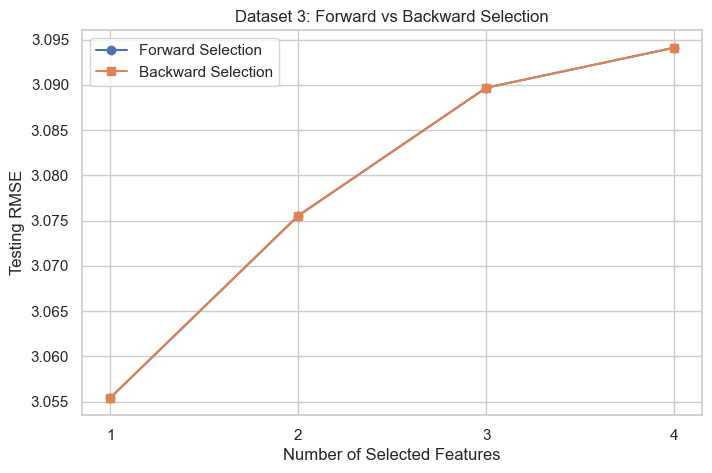

In [ ]:
# Compare forward and backward selection
plt.figure(figsize=(8, 5))

plt.plot(
    forward_results3["Number of Features"],
    forward_results3["Testing RMSE"],
    marker="o",
    label="Forward Selection"
)

plt.plot(
    backward_results3["Number of Features"],
    backward_results3["Testing RMSE"],
    marker="s",
    label="Backward Selection"
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Testing RMSE")
plt.title("Dataset 3: Forward vs Backward Selection")
plt.xticks(range(1, 5))
plt.legend()
plt.show()

### Principal Component Regression

PCR was applied to determine whether reducing the four original predictors into principal components could improve the prediction of Leads_Generated.

In [29]:
# PCR with different numbers of components
pcr_results3 = []

for n in range(1, len(features3) + 1):
    pcr = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("regression", LinearRegression())
    ])

    pcr.fit(X3_train, y3_train)
    pred = pcr.predict(X3_test)

    pcr_results3.append({
        "Components": n,
        "Testing R²": r2_score(y3_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y3_test, pred))
    })

pcr_results3 = pd.DataFrame(pcr_results3)
pcr_results3

,Components,Testing R²,Testing RMSE
0,1,-0.015162,3.084039
1,2,-0.027442,3.102638
2,3,-0.024690,3.098479
3,4,-0.021794,3.094097


PCR achieved its best performance using one principal component, with a testing R² of -0.015162 and a testing RMSE of 3.0840. The one-component PCR model improved upon the full four-feature linear regression model. However, it did not outperform the one-feature model selected through forward and backward selection. Adding additional principal components did not improve performance. These results suggest that feature selection was more effective than PCR for predicting Leads_Generated.

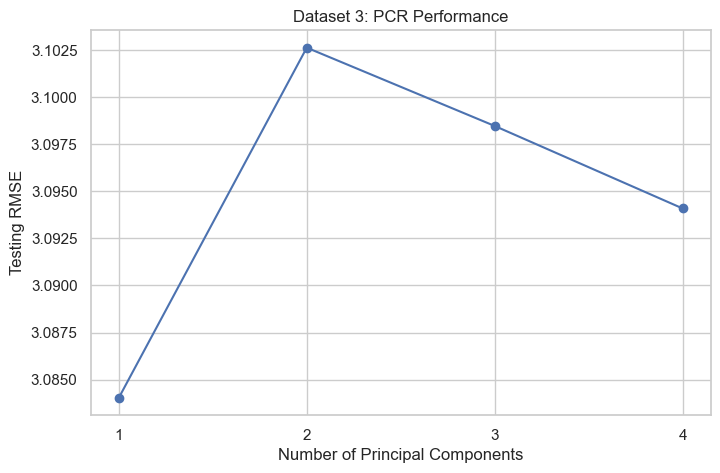

In [ ]:
# Plot PCR performance
plt.figure(figsize=(8, 5))

plt.plot(
    pcr_results3["Components"],
    pcr_results3["Testing RMSE"],
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Testing RMSE")
plt.title("Dataset 3: PCR Performance")
plt.xticks(range(1, 5))
plt.show()

### Partial Least Squares Regression

PLSR was applied to determine whether components created using information from both the predictors and Leads_Generated could improve predictive performance.

In [31]:
# PLSR with different numbers of components
plsr_results3 = []

for n in range(1, len(features3) + 1):
    plsr = Pipeline([
        ("scaler", StandardScaler()),
        ("plsr", PLSRegression(n_components=n))
    ])

    plsr.fit(X3_train, y3_train)
    pred = plsr.predict(X3_test).ravel()

    plsr_results3.append({
        "Components": n,
        "Testing R²": r2_score(y3_test, pred),
        "Testing RMSE": np.sqrt(mean_squared_error(y3_test, pred))
    })

plsr_results3 = pd.DataFrame(plsr_results3)
plsr_results3

,Components,Testing R²,Testing RMSE
0,1,-0.027655,3.102959
1,2,-0.022898,3.095768
2,3,-0.022512,3.095184
3,4,-0.021794,3.094097


PLSR produced its best testing performance using four components, with a testing R² of -0.021794 and a testing RMSE of 3.0941. The PLSR models did not outperform PCR or the forward and backward selection models. Performance generally improved as additional PLS components were added, but even the best PLSR model performed similarly to the original full linear regression model. Overall, feature selection was the most effective approach for Dataset 3.

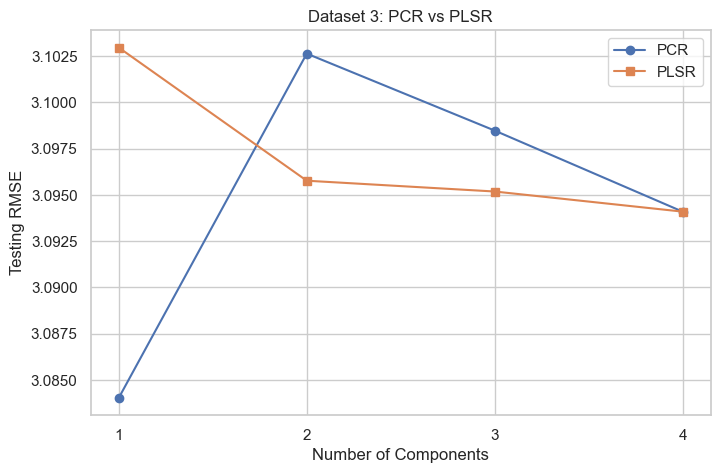

In [32]:
# Compare PCR and PLSR performance
plt.figure(figsize=(8, 5))

plt.plot(pcr_results3["Components"], pcr_results3["Testing RMSE"],
         marker="o", label="PCR")

plt.plot(plsr_results3["Components"], plsr_results3["Testing RMSE"],
         marker="s", label="PLSR")

plt.xlabel("Number of Components")
plt.ylabel("Testing RMSE")
plt.title("Dataset 3: PCR vs PLSR")
plt.xticks(range(1, 5))
plt.legend()

plt.show()

### Dataset 3 Conclusion

Forward and backward selection produced the same results, with the one-feature model using Marketing Spend achieving the best performance. This model produced a testing R² of 0.003588 and an RMSE of 3.0554, outperforming the full four-feature model. PCR performed best with one principal component and improved slightly over the full model, but it did not outperform feature selection. PLSR also failed to improve upon the selected one-feature model. Overall, Dataset 3 showed the clearest benefit from feature selection. Removing additional predictors improved testing performance, although the positive R² remained very small and indicates weak predictive ability.

In [33]:
# Best testing R² for each Week 3 method
comparison = pd.DataFrame({
    "Dataset": ["Dataset 1", "Dataset 2", "Dataset 3"],
    "Forward Selection": [
        forward_results1["Testing R²"].max(),
        forward_results2["Testing R²"].max(),
        forward_results3["Testing R²"].max()
    ],
    "Backward Selection": [
        backward_results1["Testing R²"].max(),
        backward_results2["Testing R²"].max(),
        backward_results3["Testing R²"].max()
    ],
    "PCR": [
        pcr_results1["Testing R²"].max(),
        pcr_results2["Testing R²"].max(),
        pcr_results3["Testing R²"].max()
    ],
    "PLSR": [
        plsr_results1["Testing R²"].max(),
        plsr_results2["Testing R²"].max(),
        plsr_results3["Testing R²"].max()
    ]
})

comparison

,Dataset,Forward Selection,Backward Selection,PCR,PLSR
0,Dataset 1,-0.000933,-0.000933,-0.000745,-0.000901
1,Dataset 2,-0.001018,-0.001018,-0.000633,-0.001167
2,Dataset 3,0.003588,0.003588,-0.015162,-0.021794


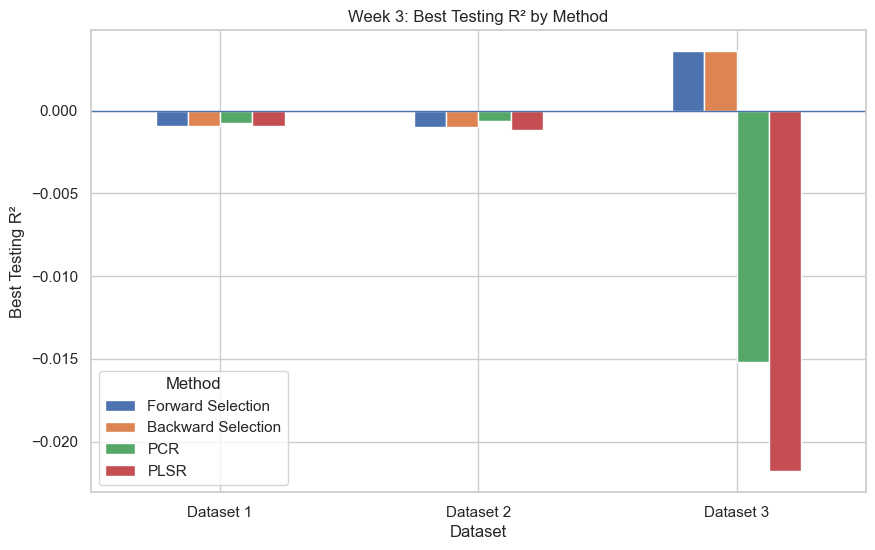

In [34]:
comparison_plot = comparison.set_index("Dataset")

comparison_plot.plot(kind="bar", figsize=(10, 6))

plt.axhline(0, linewidth=1)
plt.ylabel("Best Testing R²")
plt.xlabel("Dataset")
plt.title("Week 3: Best Testing R² by Method")
plt.xticks(rotation=0)
plt.legend(title="Method")
plt.show()